# In-depth analysis of Point to Price; Observing what makes a expensive and high score wine?

**Quality: what makes a review sound like a good wine?**

1. At the same price ($15–30), which words and phrases separate high-scoring wines (91–100) from lower-scoring ones (80–86)?
2. Are high-score words about complexity and structure (e.g. long finish, layered, age-worthy) and low-score words about simplicity or flaws (e.g. simple, short, green)?
3. Is the quality vocabulary the same for red and white wine, or does "good" mean something different for each?

**Price: what does a higher price change in the description?**

4. At the same score (87–90), which words separate expensive wines from cheap ones?
5. Are the price differences about quality (praise words) or about style (e.g. oak, polished, concentrated)?

**Back to part 3: Schachner and the Argentina/Chile confusion**

6. Do Schachner's "style" words (raw, rubbery, green, hard, jammy…) also appear when other critics describe low-scoring wines?
7. If so, did his "signature" partly reflect the cheaper, lower-scoring wines he reviews, rather than his writing style?

In [1]:
import re
from functools import lru_cache

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS
from data_processing import WINE_WORDS

df = pd.read_pickle("processed_reviews.pkl")


[nltk_data] Error loading wo9rdnet: Package 'wo9rdnet' not found in
[nltk_data]     index


In [ ]:
lemmatizer = WordNetLemmatizer()
TOKEN_PATTERN = r"(?u)\b[a-z][a-z'-]+\b"

@lru_cache(maxsize=None)
def lemma(word):
    return lemmatizer.lemmatize(word)

def lemma_tokenizer(text):
    return [lemma(t) for t in re.findall(TOKEN_PATTERN, text)]

NEGATIONS = {"not", "no", "nor", "without"}
EDGE_STOPS = (set(ENGLISH_STOP_WORDS) - NEGATIONS) | WINE_WORDS
EDGE_STOPS |= {lemma(w) for w in EDGE_STOPS}

COUNTRY_WORDS = {
    "american", "italian", "spanish", "chilean", "australian", "aussie",
    "argentine", "argentinean", "argentinian", "portuguese", "african",
    "european", "europe", "californian", "oregonian", "tuscan", "sicilian",
    "burgundian", "alsatian", "sardinian", "patagonian", "galician", "catalan",
    "iberian", "iberia", "umbrian", "piedmontese", "provencal", "calabrian",
    "venetian", "lombard", "bordelais", "castilian", "french", "old-world", "new-world",
}
BOILERPLATE = {"varietyname", "drink"} | COUNTRY_WORDS

def get_text(d):
    return (d["description_masked"]
              .str.lower()
              .str.replace(r"['’]s\b", "", regex=True) 
              .str.replace(r"\b(french|american|hungarian)\s+oak\b", "oak", regex=True))

def keep_phrase(phrase):
    words = phrase.split()
    if words[0] in EDGE_STOPS or words[-1] in EDGE_STOPS:
        return False
    if "old world" in phrase or "new world" in phrase:
        return False
    return not any(w in BOILERPLATE or w in place_words for w in words) # will create place words in next cell


In [7]:
SCORE_BINS, SCORE_LABELS = [79, 86, 90, 100], ["80-86", "87-90", "91-100"]
PRICE_BINS, PRICE_LABELS = [0, 15, 30, 60, np.inf], ["≤15", "15-30", "30-60", "60+"]

df_still = df[df["color"].isin(["red", "white"]) & (df["category"] == "still") & df["price"].notna()].copy()
df_still["score_band"] = pd.cut(df_still["points"], SCORE_BINS, labels=SCORE_LABELS)
df_still["price_band"] = pd.cut(df_still["price"], PRICE_BINS, labels=PRICE_LABELS)

place_words = set()
for col in ["country", "province", "region_1", "region_2"]:
    for name in df_still[col].dropna().unique():
        place_words.update(lemma_tokenizer(name.lower()))

pd.crosstab([df_still["color"], df_still["score_band"]], df_still["price_band"])


price_band          ≤15  15-30  30-60   60+
color score_band                           
red   80-86       10893  10839   4460   629
      87-90        5720  18882  15056  3531
      91-100        218   4111  12750  8952
white 80-86        9054   6496    753    44
      87-90        5631  13687   3747   467
      91-100        187   3394   4234  1853

In [8]:
def compare_groups(data, is_a, ngram_range=(1,2), min_df=20):
    """
    % of group A vs group B reviews that use each others' phrases 
    """
    counter = CountVectorizer(ngram_range=ngram_range, min_df=min_df, binary=True, tokenizer=lemma_tokenizer, token_pattern=None)

    X = counter.fit_transform(get_text(data))
    comp = pd.DataFrame({
        "term": counter.get_feature_names_out(),
        "pct_a": 100 * np.asarray(X[is_a].mean(axis=0)).ravel(),
        "pct_b": 100 * np.asarray(X[~is_a].mean(axis=0)).ravel()
    })

    comp = comp[[keep_phrase(t) for t in comp["term"]]]
    comp["diff"] = comp["pct_a"] - comp["pct_b"]
    return comp

In [9]:
def plot_comparison(comp, label_a, label_b, title, top_n=20):
    panels = [(comp.nlargest(top_n, "diff"),  "pct_a", "pct_b", label_a),
              (comp.nsmallest(top_n, "diff"), "pct_b", "pct_a", label_b)]

    fig, axes = plt.subplots(1, 2, figsize=(13, 7))
    for ax, (d, own, other, name) in zip(axes, panels):
        ax.barh(d["term"], d[own], color="#2a78d6", height=0.7)
        ax.scatter(d[other], d["term"], color="#8a8984", s=30, zorder=3,
                   edgecolor="white", linewidth=1.5)
        ax.invert_yaxis()
        ax.set_title(f"Used more in {name}", loc="left", fontsize=11)
        ax.spines[["top", "right"]].set_visible(False)
        ax.grid(axis="x", color="#e5e4e0", linewidth=0.8)
        ax.set_axisbelow(True)
        ax.tick_params(length=0)
        ax.set_xlabel("% of reviews that use the term")
        ax.legend(handles=[Patch(color="#2a78d6", label="This group"),
                           Line2D([], [], marker="o", color="w", markerfacecolor="#8a8984",
                                  markersize=7, label="Other group")],
                  loc="lower right", frameon=False)

    fig.suptitle(title, x=0.01, ha="left", fontsize=13)
    plt.tight_layout()
    plt.show()


high: 4,111 | low: 10,839


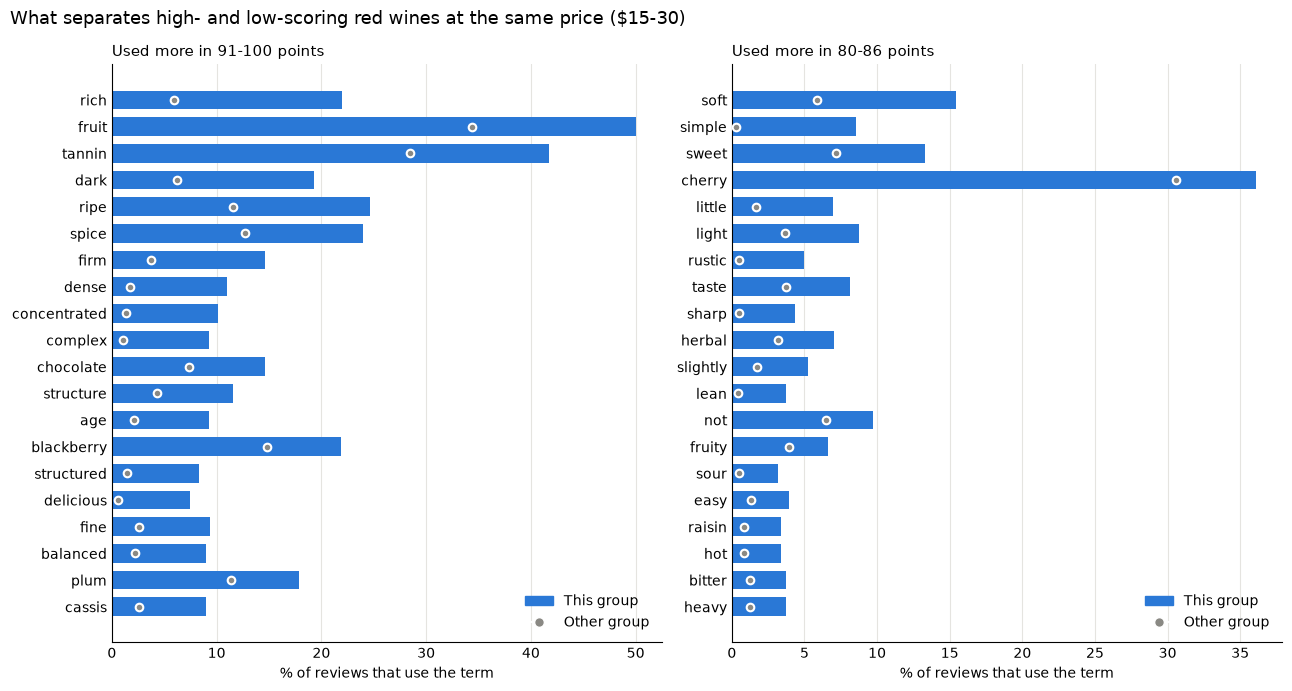

In [ ]:
red_1530 = df_still[(df_still["color"] == "red") & (df_still["price_band"] == "15-30") & (df_still["score_band"].isin(["80-86", "91-100"]))]
is_high = (red_1530["score_band"] == "91-100").to_numpy() # converts to True and False 
print(f"high: {is_high.sum():,} | low: {(~is_high).sum():,}")

quality_red = compare_groups(red_1530, is_high)
plot_comparison(quality_red, "91-100 points", "80-86 points", "What separates high- and low-scoring red wines at the same price ($15-30)")


$60+: 3,531 | ≤$15: 5,720


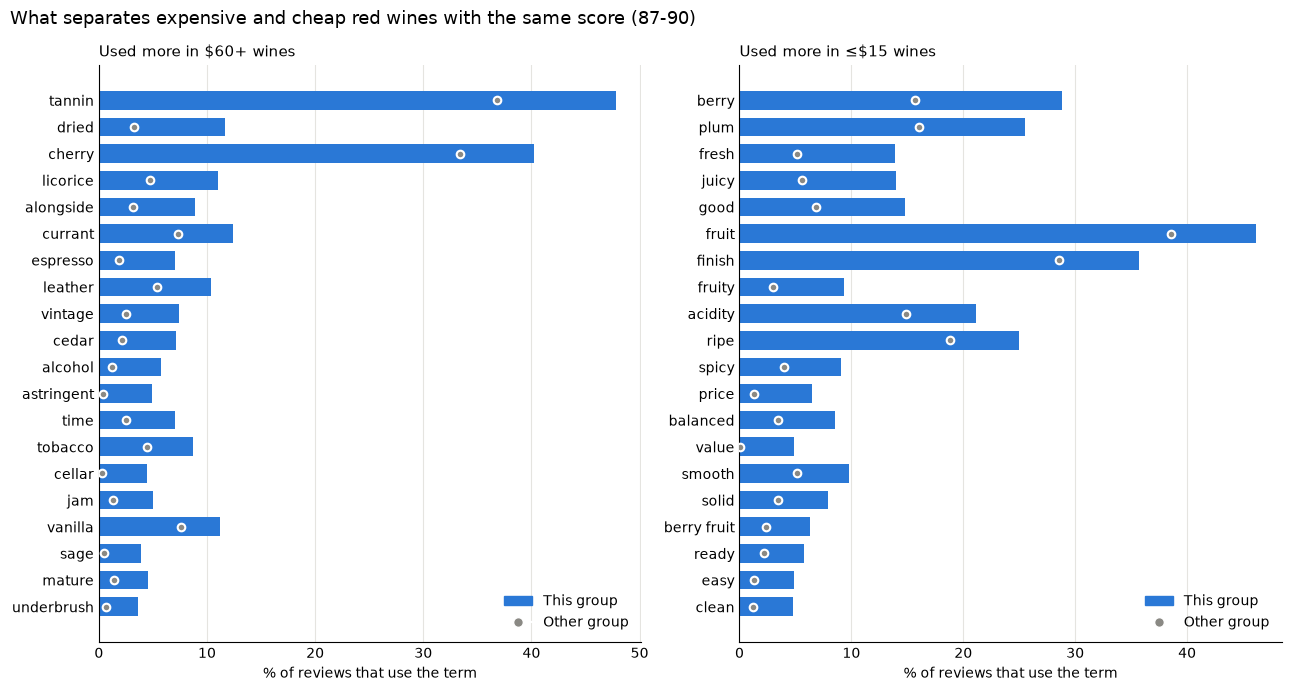

In [11]:
red_8790 = df_still[(df_still["color"] == "red") & (df_still["score_band"] == "87-90") & (df_still["price_band"].isin(["≤15", "60+"]))]
is_pricey = (red_8790["price_band"] == "60+").to_numpy() # converts to true and false 
print(f"$60+: {is_pricey.sum():,} | ≤$15: {(~is_pricey).sum():,}")

price_red = compare_groups(red_8790, is_pricey)
plot_comparison(price_red, "$60+ wines", "≤$15 wines", "What separates expensive and cheap red wines with the same score (87-90)")


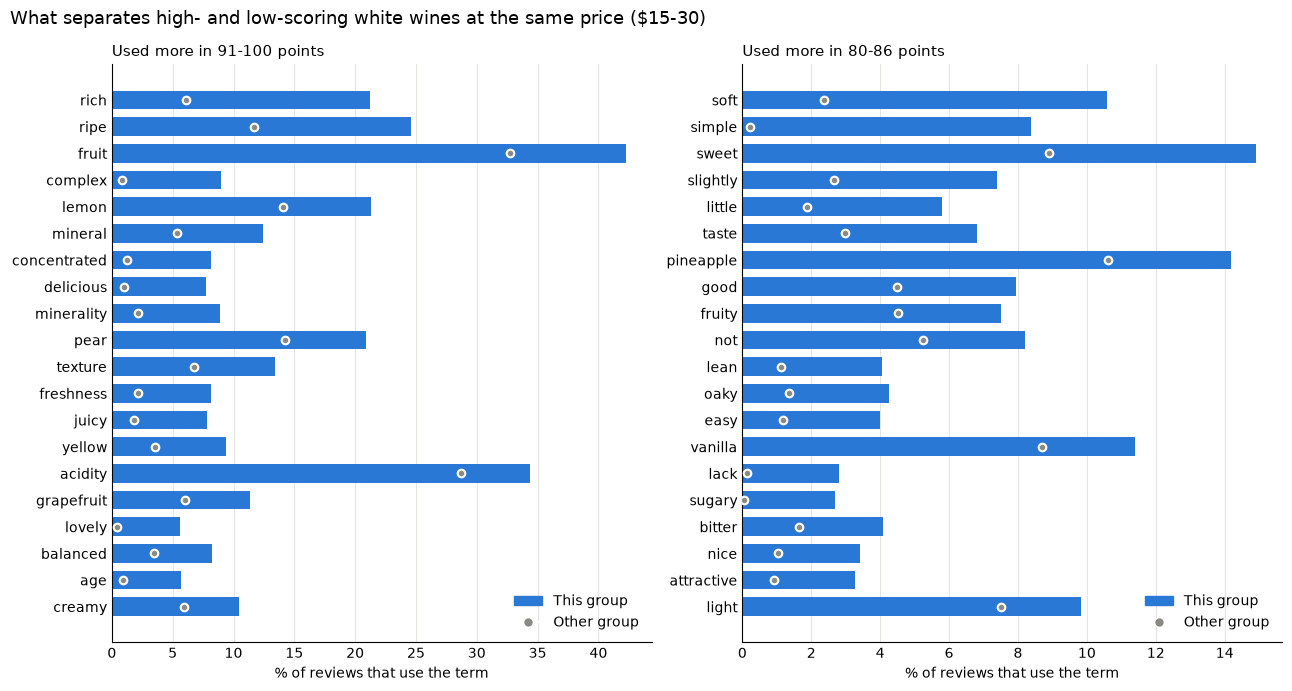

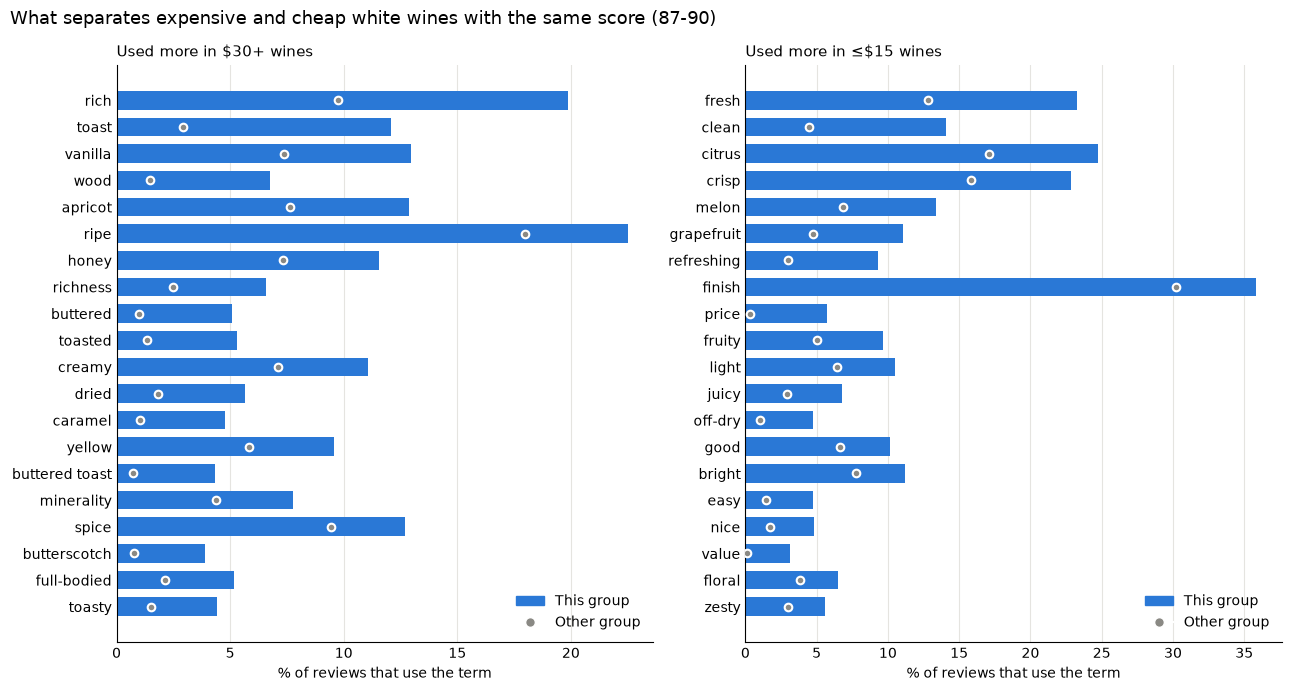

In [12]:
white_1530 = df_still[(df_still["color"] == "white") & (df_still["price_band"] == "15-30")
                      & (df_still["score_band"].isin(["80-86", "91-100"]))]
quality_white = compare_groups(white_1530, (white_1530["score_band"] == "91-100").to_numpy())
plot_comparison(quality_white, "91-100 points", "80-86 points",
                "What separates high- and low-scoring white wines at the same price ($15-30)")

white_8790 = df_still[(df_still["color"] == "white") & (df_still["score_band"] == "87-90")
                      & (df_still["price_band"].isin(["≤15", "30-60", "60+"]))]
price_white = compare_groups(white_8790, white_8790["price_band"].isin(["30-60", "60+"]).to_numpy())
plot_comparison(price_white, "$30+ wines", "≤$15 wines",
                "What separates expensive and cheap white wines with the same score (87-90)")


In [ ]:
SCHACHNER_STYLE = {"baked", "berry", "cassis", "chunky", "earthy", "finish", "good", "grabby",
                   "green", "hard", "heavy", "herbal", "jammy", "minty", "oaky", "plum", "raw",
                   "roasted", "rubbery", "spicy", "tannic", "taste", "tomato"}

no_ms = red_1530[red_1530["taster_name"] != "Michael Schachner"]
quality_no_ms = compare_groups(no_ms, (no_ms["score_band"] == "91-100").to_numpy())

low_100  = set(quality_no_ms.nsmallest(100, "diff")["term"])
high_100 = set(quality_no_ms.nlargest(100, "diff")["term"])

print("Schachner style words that other critics also use for LOW scores: ", sorted(SCHACHNER_STYLE & low_100))
print("Schachner style words that other critics also use for HIGH scores:", sorted(SCHACHNER_STYLE & high_100))
print("Neither (more likely his own habit):                             ", sorted(SCHACHNER_STYLE - low_100 - high_100))


Schachner style words that other critics also use for LOW scores:  ['baked', 'earthy', 'finish', 'good', 'hard', 'heavy', 'herbal', 'jammy', 'minty', 'oaky', 'raw', 'taste', 'tomato']
Schachner style words that other critics also use for HIGH scores: ['berry', 'cassis', 'plum']
Neither (more likely his own habit):                              ['chunky', 'grabby', 'green', 'roasted', 'rubbery', 'spicy', 'tannic']
